In [2]:
# Imports
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import os
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from scipy.interpolate import griddata
import matplotlib.cm as cm
import matplotlib.colors as colors
import imageio
import glob

In [3]:
# --- Load Water Mass Codes ---
# Load the manual and correctly rename the columns
manual_filepath = '../sources/水環境総合情報サイト/water_manual.xls'
codes_df = pd.read_excel(manual_filepath, sheet_name='3. Water mass code', header=3)
codes_df = codes_df.rename(columns={
    'Water Mass Code': 'watercode',
    'Water Mass Name': 'watermass_name',
    'Water Mass Division': 'division',
    'Water Mass Details': 'details'
}) #[cite: 41, 44-49]

# --- Load and Combine Yearly Environmental Data ---
base_data_path = '../data/raw/environmental_data' #[cite: 159]
gdfs = []
for dirpath, _, filenames in os.walk(base_data_path):
    if 'output.shp' in filenames: #[cite: 164, 165]
        # Extract year from the folder name
        try:
            year = int(os.path.basename(dirpath).split('_')[0]) #[cite: 168]
        except (ValueError, IndexError):
            continue
        
        # Read shapefile, add year, and append to list
        shp_filepath = os.path.join(dirpath, 'output.shp') #[cite: 171]
        gdf_temp = gpd.read_file(shp_filepath) #[cite: 172]
        gdf_temp['year'] = year #[cite: 173]
        gdfs.append(gdf_temp) #[cite: 174]

# Concatenate all yearly data into one GeoDataFrame
all_points_gdf = pd.concat(gdfs, ignore_index=True) #[cite: 177]
print(f"Loaded and combined {len(all_points_gdf)} data points from {len(gdfs)} files.")

Loaded and combined 41346 data points from 84 files.


In [4]:
# --- Merge Datasets ---
# Ensure 'watercode' columns are the same integer type before merging
all_points_gdf['watercode'] = all_points_gdf['watercode'].astype(int) #[cite: 270]
codes_df['watercode'] = codes_df['watercode'].astype(int) #[cite: 270]
merged_gdf = all_points_gdf.merge(codes_df, on='watercode', how='left') #[cite: 277]

# --- Create Season Column ---
def get_season(month): #[cite: 548]
    """Takes a month (1-12) and returns the corresponding season.""" #[cite: 549]
    if month in [12, 1, 2]: return 'Winter' #[cite: 550]
    elif month in [3, 4, 5]: return 'Spring' #[cite: 551]
    elif month in [6, 7, 8, 9]: return 'Summer' #[cite: 552]
    elif month in [10, 11]: return 'Autumn' #[cite: 553]
    else: return 'Unknown' #[cite: 556]

merged_gdf['season'] = merged_gdf['surveymont'].apply(get_season) #[cite: 557]

# --- Final Cleanup ---
# Ensure 'do_' column is a numeric type for calculations
merged_gdf['do_'] = pd.to_numeric(merged_gdf['do_'], errors='coerce') #[cite: 688]

print("Data merged and 'season' column created successfully.")
print(f"Merged dataset contains {len(merged_gdf)} records.")
print(merged_gdf[['year', 'surveymont', 'season', 'division']].head()) #[cite: 561]

Data merged and 'season' column created successfully.
Merged dataset contains 41346 records.
   year  surveymont  season   division
0  1981           5  Spring  Osaka Bay
1  1981           8  Summer  Osaka Bay
2  1981           1  Winter  Osaka Bay
3  1981           5  Spring  Osaka Bay
4  1981           8  Summer  Osaka Bay


In [5]:
# Filter for summer bottom-layer data with valid DO measurements
analysis_df = merged_gdf[
    (merged_gdf['saisuipoin'] == 2)
].dropna(subset=['do_']).copy()

print(f"Prepared {len(analysis_df)} data points for analysis.")

vmin = analysis_df['do_'].min()
vmax = analysis_df['do_'].max()

Prepared 20631 data points for analysis.


In [6]:
# # Best practice
# # This is a more optimized version of the code. Instead of a loop and executing it right away, we define functions and call them as needed.
# # This way, I can test individual parts of the code without running the entire loop every time

# def create_yearly_heatmap(year, data, vmin, vmax, output_dir):
#     """Generates and saves a single DO heatmap for a given year."""
    
#     year_data = data[data['year'] == year]
#     if len(year_data) < 4:
#         print(f"Not enough data for {year}, skipping.")
#         return # Exit the function

#     # --- Interpolation ---
#     points = np.array([year_data.geometry.x, year_data.geometry.y]).T
#     values = year_data['do_'].values
#     grid_x, grid_y = np.mgrid[130.6:135.6:200j, 32.75:35.1:200j]
#     grid_z = griddata(points, values, (grid_x, grid_y), method='cubic')

#     # --- Plotting ---
#     fig = plt.figure(figsize=(12, 10))
#     ax = plt.axes(projection=ccrs.PlateCarree())
#     ax.set_extent([130.6, 135.6, 32.75, 35.1], crs=ccrs.PlateCarree())
#     ax.add_feature(cfeature.OCEAN, zorder=0)
#     ax.add_feature(cfeature.LAND, edgecolor='black', zorder=2)
#     ax.add_feature(cfeature.COASTLINE, zorder=2)
#     ax.add_feature(cfeature.BORDERS, linestyle=':', zorder=2)
    
#     contour = ax.contourf(
#         grid_x, grid_y, grid_z,
#         levels=np.linspace(vmin, vmax, 15),
#         cmap='jet_r', transform=ccrs.PlateCarree(),
#         zorder=1
#     )
    
#     cbar = fig.colorbar(contour, ax=ax, fraction=0.1, pad=0.5)
#     cbar.set_label('Interpolated DO (mg/L)')
#     ax.set_title(f'Summer Bottom DO Distribution for {year}')

#     # Save and close the figure
#     output_path = os.path.join(output_dir, f'frame_{year}.png')
#     plt.savefig(output_path, dpi=150, bbox_inches='tight')
#     plt.close(fig)
#     print(f"Saved map for {year}.")

In [7]:
# # --- Test Cell ---
# # Test the function with a single year
# # 1. Define the parameters
# test_year = 2022
# data_source = analysis_df # Your prepared data
# output_dir = '../reports/figures/seasonal_gif_frames'
# os.makedirs(output_dir, exist_ok=True)

# # 2. Call the function with the prepared variables
# create_yearly_heatmap(
#     year=test_year,
#     data=data_source,
#     vmin=vmin,
#     vmax=vmax,
#     output_dir=output_dir
# )

# # show the saved file
# from IPython.display import Image
# Image(filename=f'../reports/figures/seasonal_gif_frames/frame_{test_year}.png')

Saved frame for 2022 to ../reports/figures/seasonal_gif_frames\frame_2022.png


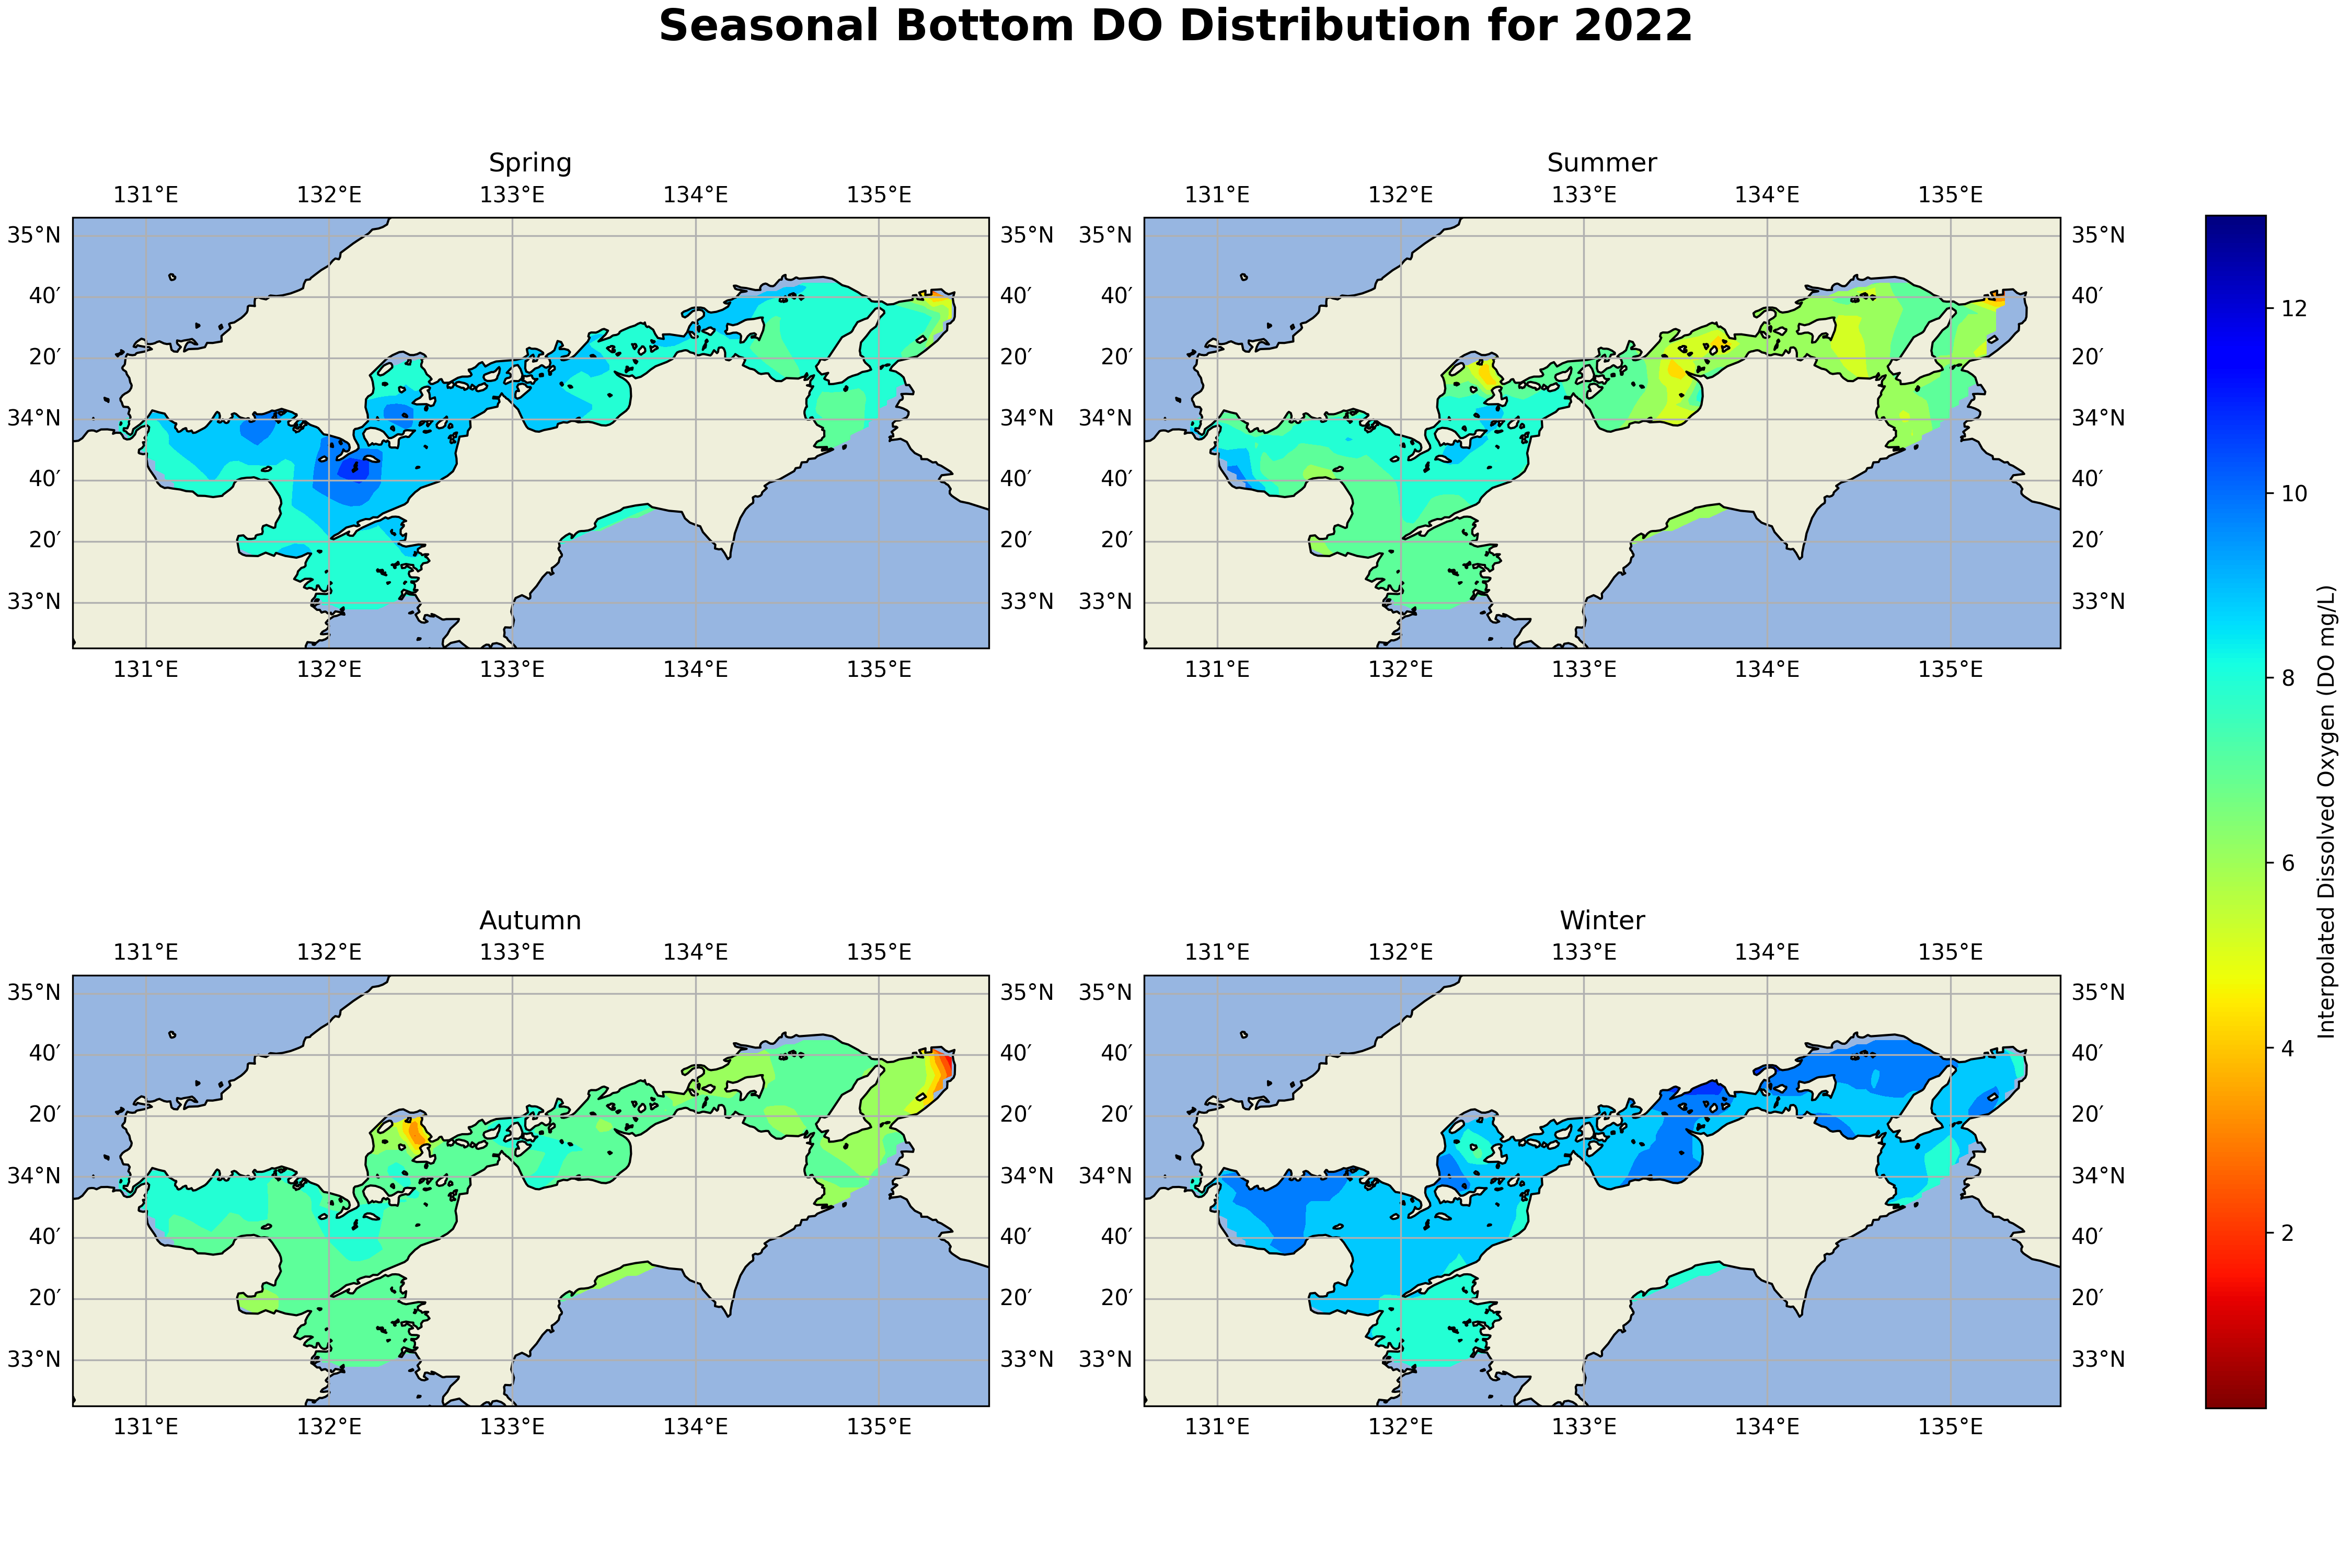

In [ ]:
def create_seasonal_maps_for_year(year, data, vmin, vmax, output_dir):
    """
    Generates and saves a 2x2 grid of seasonal DO heatmaps for a given year.
    """
    # --- Create the 2x2 subplot figure ---
    fig, axes = plt.subplots(
        2, 2, figsize=(15, 10),
        subplot_kw={'projection': ccrs.PlateCarree()},
        constrained_layout=True
    )
    fig.suptitle(f'Seasonal Bottom DO Distribution for {year}', fontsize=20, fontweight='bold')
    # Flatten the 2x2 axes array for easy iteration
    axes = axes.flatten()
    
    # Store the last contour plot to use for the single, shared colorbar
    last_contour = None
    seasons = ['Spring', 'Summer', 'Autumn', 'Winter']
    extent = [130.6, 135.6, 32.75, 35.1]
    grid_res_x, grid_res_y = (100j, 100j)

    # --- Inner loop to create a map for each season ---
    for i, season in enumerate(seasons):
        ax = axes[i]
        ax.set_extent(extent, crs=ccrs.PlateCarree())
        ax.add_feature(cfeature.OCEAN, zorder=0)
        ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False, zorder=3)
        ax.set_title(season)

        # Filter data for the specific year AND season
        year_season_data = data[
            (data['year'] == year) &
            (data['season'] == season)
        ]
        
        if len(year_season_data) > 3:
            # --- Interpolation ---
            points = np.array([year_season_data.geometry.x, year_season_data.geometry.y]).T
            values = year_season_data['do_'].values
            grid_x, grid_y = np.mgrid[extent[0]:extent[1]:grid_res_x, extent[2]:extent[3]:grid_res_y]
            grid_z = griddata(points, values, (grid_x, grid_y), method='cubic')

            # --- Plotting the heatmap ---
            contour = ax.contourf(
                grid_x, grid_y, grid_z,
                levels=np.linspace(vmin, vmax, 15),
                cmap='jet_r', vmin=vmin, vmax=vmax,
                transform=ccrs.PlateCarree(), zorder=1
            )
            last_contour = contour
        else:
            ax.text(0.5, 0.5, 'No Data', transform=ax.transAxes, ha='center', va='center', fontsize=15)
    
        # --- PRESERVE STYLE: Draw Land and Coastlines on TOP of the heatmap ---
        ax.add_feature(cfeature.LAND, edgecolor='black', zorder=1)
        #ax.add_feature(cfeature.COASTLINE, zorder=2)
        
    # --- PRESERVE STYLE: Add a single colorbar for the whole figure ---
    if last_contour:
        norm = colors.Normalize(vmin=vmin, vmax=vmax)
        mappable = cm.ScalarMappable(norm=norm, cmap='jet_r')
        cbar = fig.colorbar(mappable, ax=axes, orientation='vertical', fraction=0.03, pad=0.04)
        cbar.set_label('Interpolated Dissolved Oxygen (DO mg/L)')

    # Save the composite figure for the year
    output_path = os.path.join(output_dir, f'frame_{year}.png')
    plt.savefig(output_path, dpi=300) # Removed bbox_inches='tight' for consistency
    plt.close(fig)
    print(f"Saved frame for {year} to {output_path}")

# --- Setup your parameters once ---
output_dir = '../reports/figures/seasonal_gif_frames'
os.makedirs(output_dir, exist_ok=True)
years = sorted(analysis_df['year'].unique())

# --- Call the function for a single year to test ---
test_year = 2022
create_seasonal_maps_for_year(test_year, analysis_df, vmin, vmax, output_dir)

# show the saved file
from IPython.display import Image
Image(filename=f'../reports/figures/seasonal_gif_frames/frame_{test_year}.png')

Saved frame for 1981 to ../reports/figures/seasonal_gif_frames\frame_1981.png


KeyboardInterrupt: 

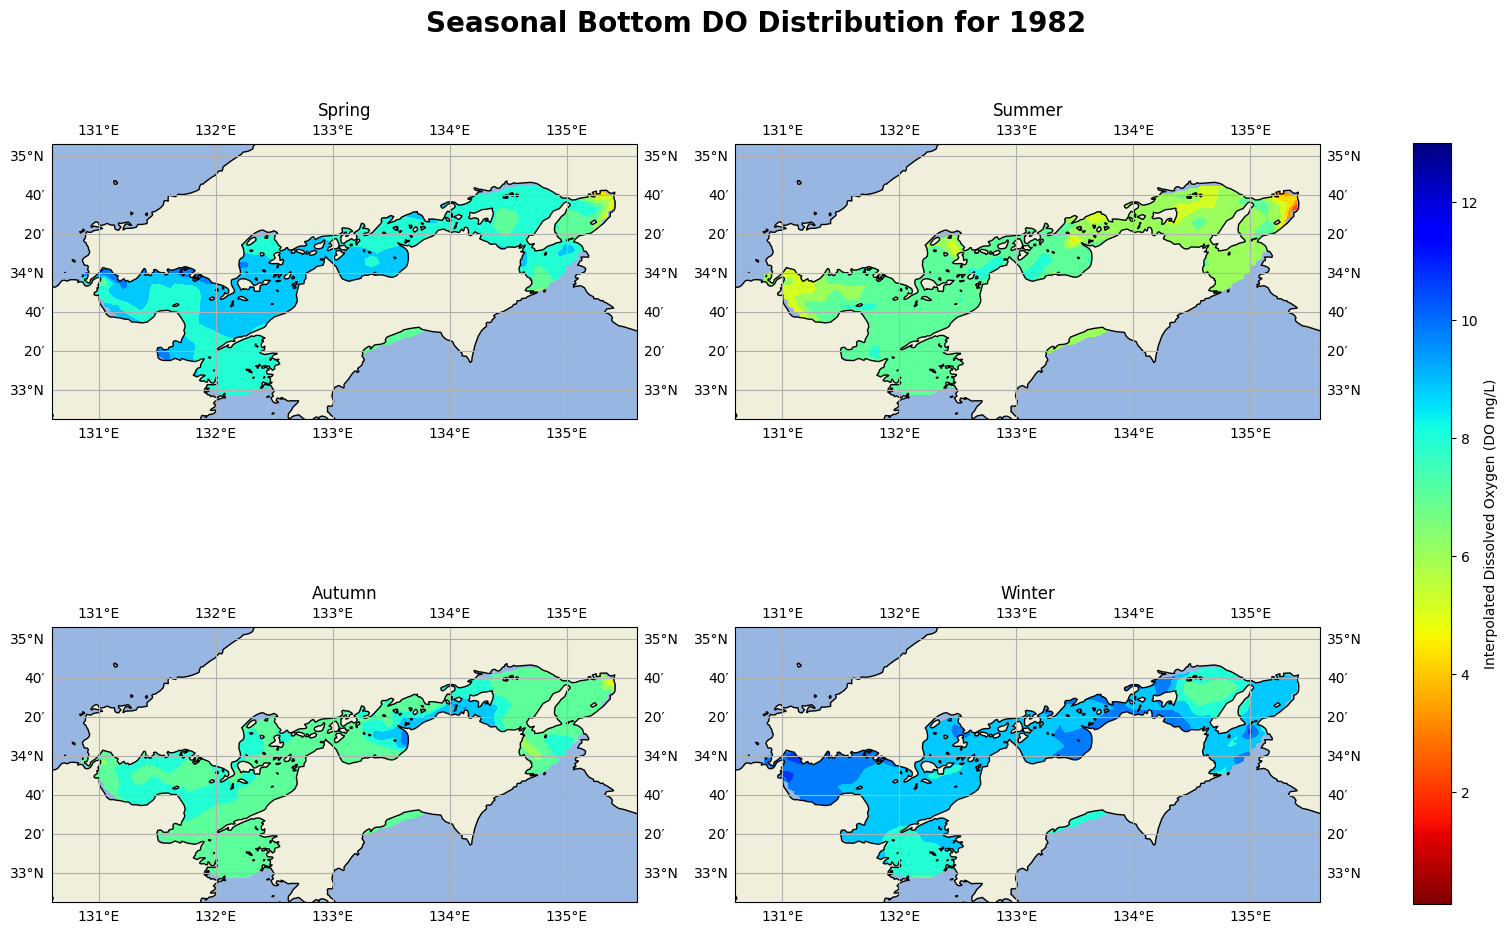

In [9]:
# --- Production Loop --- (LATER)
for year in years:
    create_seasonal_maps_for_year(year, analysis_df, vmin, vmax, output_dir)

print("\nAll seasonal maps have been generated.")

In [ ]:
# --- 5. Create the Final GIF Animation ---
print("\nStitching frames into a GIF...")
images = []
file_list = sorted(glob.glob(os.path.join(output_dir, '*.png')))

for filename in file_list:
    images.append(imageio.imread(filename))

gif_path = '../reports/figures/animations/seasonal_do_animation.gif'
imageio.mimsave(gif_path, images, fps=1) # 1 second per year

print(f"✅ Animation saved successfully to {gif_path}")


Stitching frames into a GIF...


C:\Users\reyha\AppData\Local\Temp\ipykernel_30820\973872077.py:7: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  images.append(imageio.imread(filename))


✅ Animation saved successfully to ../reports/figures/animations/seasonal_do_animation.gif
